# Does attacker size change recovery against one frozen Alice–Bob pair?

Run top to bottom in **Google Colab with one A100 GPU**. This is a single-seed, 32-bit comparison. Stage 1 trains one Alice–Bob pair against one CNN Eve; all three have **40,609 trainable parameters**. Stage 2 freezes that exact Alice and sweeps fresh attacker sizes within each of four architecture families: CNN, MLP, BiLSTM, and Transformer. Within a family, only width changes to reach the configured parameter targets. Each attacker receives the same pseudorandom sequence of training examples, the same optimizer and step budget, and the same held-out evaluation set. Neither fresh attacker sees the key.

The notebook prints progress and a machine-readable `RESULT_JSON` line immediately after each completed attacker. Its figure updates after each architecture family. It creates **no checkpoints, CSVs, or image files**. To keep printed results and figures after a Colab disconnect, save the executed notebook in Drive (or download the executed `.ipynb`). An interrupted training cell cannot resume without a checkpoint; only its already printed output may survive. A one-seed comparison is descriptive evidence for this pair, not a general claim that larger models always attack better.

The training CNN Eve receives the 32-value ciphertext twice in a fixed rearrangement so it can use exactly the same 64-input CNN as Alice and Bob. This adds no message or key information; because the second half is redundant, the nominal parameter count is exactly matched but its effective input dimension remains 32.

In [ ]:
import json
import random
import time
from contextlib import nullcontext

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from IPython.display import display
from torch import nn

SEED = 7
MESSAGE_BITS = KEY_BITS = CIPHER_BITS = 32
TARGET_SIZES = (5_000, 10_000, 20_000, 40_000, 80_000)
TRAIN_STEPS = 5_000
ATTACK_STEPS = 5_000
EVE_UPDATES = 2
BATCH_SIZE = 16_384
EVAL_SIZE = 16_384
LOG_EVERY = 1000
AB_LR = 8e-4
ATTACK_LR = 1e-3
PRIVACY_WEIGHT = 8.0

assert torch.cuda.is_available(), "Select an A100 GPU runtime in Colab."
device = torch.device("cuda")
gpu_name = torch.cuda.get_device_name(0)
print(f"GPU: {gpu_name}; PyTorch: {torch.__version__}", flush=True)
if "A100" not in gpu_name:
    print("NOTE: Configured for one A100; another GPU may need a smaller BATCH_SIZE.", flush=True)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision("high")

def amp():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def count(model):
    return sum(p.numel() for p in model.parameters())

def random_batch(n, generator=None):
    m = torch.randint(0, 2, (n, MESSAGE_BITS), generator=generator, device=device).float() * 2 - 1
    k = torch.randint(0, 2, (n, KEY_BITS), generator=generator, device=device).float() * 2 - 1
    return m, k

def decode_accuracy(prediction, message):
    return (torch.where(prediction >= 0, 1., -1.) == message).float().mean().item()

def full_accuracy(prediction, message):
    return (torch.where(prediction >= 0, 1., -1.) == message).all(dim=1).float().mean().item()

def reconstruction_loss(prediction, message):
    return ((prediction - message).abs() / 2).sum(dim=1).mean()

def cnn_eve_input(ciphertext):
    return torch.cat((ciphertext, ciphertext.roll(1, dims=1)), dim=1)

class CryptCNN(nn.Module):
    """Same 40,609-parameter CNN for Alice, Bob, and training Eve."""
    def __init__(self):
        super().__init__()
        self.mix = nn.Linear(64, 192)
        self.conv1 = nn.Conv1d(1, 48, 5, padding="same")
        self.conv2 = nn.Conv1d(48, 96, 4, stride=2, padding=1)
        self.conv3 = nn.Conv1d(96, 48, 2, stride=3)
        self.conv4 = nn.Conv1d(48, 1, 1)

    def forward(self, values):
        x = self.mix(values).unsqueeze(1)
        x = torch.sigmoid(self.conv1(x))
        x = torch.sigmoid(self.conv2(x))
        x = torch.sigmoid(self.conv3(x))
        return torch.tanh(self.conv4(x).squeeze(1))

class FreshCNNEve(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.mix = nn.Linear(32, 128)
        self.conv1 = nn.Conv1d(1, width, 5, padding="same")
        self.conv2 = nn.Conv1d(width, 2 * width, 4, stride=2, padding=1)
        self.conv3 = nn.Conv1d(2 * width, width, 2, stride=2)
        self.conv4 = nn.Conv1d(width, 1, 1)

    def forward(self, ciphertext):
        x = self.mix(ciphertext).unsqueeze(1)
        x = torch.sigmoid(self.conv1(x))
        x = torch.sigmoid(self.conv2(x))
        x = torch.sigmoid(self.conv3(x))
        return torch.tanh(self.conv4(x).squeeze(1))

class MLPEve(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(32, width), nn.ReLU(),
                                 nn.Linear(width, width), nn.ReLU(),
                                 nn.Linear(width, 32), nn.Tanh())

    def forward(self, ciphertext):
        return self.net(ciphertext)

class BiLSTMEve(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.lstm = nn.LSTM(1, width, batch_first=True, bidirectional=True)
        self.readout = nn.Linear(2 * width, 1)

    def forward(self, ciphertext):
        sequence, _ = self.lstm(ciphertext.unsqueeze(-1))
        return torch.tanh(self.readout(sequence).squeeze(-1))

class TransformerEve(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.input_projection = nn.Linear(1, width)
        self.position = nn.Parameter(torch.zeros(1, 32, width))
        layer = nn.TransformerEncoderLayer(width, 4, 2 * width,
                                            dropout=0.0, batch_first=True,
                                            activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, num_layers=2,
                                             enable_nested_tensor=False)
        self.readout = nn.Linear(width, 1)

    def forward(self, ciphertext):
        x = self.input_projection(ciphertext.unsqueeze(-1)) + self.position
        return torch.tanh(self.readout(self.encoder(x)).squeeze(-1))

FAMILIES = {"CNN": FreshCNNEve, "MLP": MLPEve,
            "BiLSTM": BiLSTMEve, "Transformer": TransformerEve}

def choose_width(family, target):
    candidates = range(8, 321, 4) if family == "Transformer" else range(8, 321)
    width = min(candidates, key=lambda w: abs(count(FAMILIES[family](w)) - target))
    model = FAMILIES[family](width)
    return width, count(model)

size_plan = {family: {target: choose_width(family, target) for target in TARGET_SIZES}
             for family in FAMILIES}
set_seed(SEED)
alice, bob, training_eve = (CryptCNN().to(device) for _ in range(3))
assert count(alice) == count(bob) == count(training_eve) == 40_609
with torch.no_grad():
    m, k = random_batch(2)
    assert alice(torch.cat((m, k), dim=1)).shape == m.shape
    assert training_eve(cnn_eve_input(m)).shape == m.shape
print(f"Seed: {SEED}; message/key/ciphertext: 32 bits; batch: {BATCH_SIZE:,}", flush=True)
print(f"Stage 1 parameters: Alice={count(alice):,}, Bob={count(bob):,}, "
      f"training CNN Eve={count(training_eve):,}", flush=True)
for family, sizes in size_plan.items():
    for target, (width, actual) in sizes.items():
        print(f"Stage 2 {family:11s} target={target:,} width={width} actual={actual:,}", flush=True)
print(f"Stage 1: {TRAIN_STEPS:,} steps, {EVE_UPDATES} Eve updates/step; "
      f"each fresh attacker: {ATTACK_STEPS:,} steps; held-out: {EVAL_SIZE:,} messages", flush=True)

GPU: NVIDIA A100-SXM4-40GB; PyTorch: 2.11.0+cu130
Seed: 7; message/key/ciphertext: 32 bits; batch: 16,384
Stage 1 parameters: Alice=40,609, Bob=40,609, training CNN Eve=40,609
Stage 2 CNN         target=5,000 width=8 actual=5,073
Stage 2 CNN         target=10,000 width=22 actual=10,253
Stage 2 CNN         target=20,000 width=36 actual=20,137
Stage 2 CNN         target=40,000 width=54 actual=39,757
Stage 2 CNN         target=80,000 width=79 actual=79,907
Stage 2 MLP         target=5,000 width=45 actual=5,027
Stage 2 MLP         target=10,000 width=72 actual=9,968
Stage 2 MLP         target=20,000 width=112 actual=19,968
Stage 2 MLP         target=40,000 width=170 actual=40,152
Stage 2 MLP         target=80,000 width=252 actual=80,168
Stage 2 BiLSTM      target=5,000 width=23 actual=4,831
Stage 2 BiLSTM      target=10,000 width=34 actual=10,133
Stage 2 BiLSTM      target=20,000 width=48 actual=19,681
Stage 2 BiLSTM      target=40,000 width=69 actual=39,883
Stage 2 BiLSTM      target=80,0

In [ ]:
# Stage 1. Run once; all eight attackers below use this exact frozen Alice.
ab_optimizer = torch.optim.Adam(list(alice.parameters()) + list(bob.parameters()), lr=AB_LR)
eve_optimizer = torch.optim.Adam(training_eve.parameters(), lr=ATTACK_LR)
start = time.monotonic()
alice.train(); bob.train(); training_eve.train()
for step in range(1, TRAIN_STEPS + 1):
    for _ in range(EVE_UPDATES):
        message, key = random_batch(BATCH_SIZE)
        with torch.no_grad(), amp():
            ciphertext = alice(torch.cat((message, key), dim=1))
        with amp():
            eve_loss = reconstruction_loss(training_eve(cnn_eve_input(ciphertext)), message)
        eve_optimizer.zero_grad(set_to_none=True)
        eve_loss.backward()
        eve_optimizer.step()

    message, key = random_batch(BATCH_SIZE)
    training_eve.requires_grad_(False)
    with amp():
        ciphertext = alice(torch.cat((message, key), dim=1))
        bob_out = bob(torch.cat((ciphertext, key), dim=1))
        eve_out = training_eve(cnn_eve_input(ciphertext))
        bob_loss = reconstruction_loss(bob_out, message)
        eve_error = reconstruction_loss(eve_out, message)
        privacy_loss = ((MESSAGE_BITS / 2 - eve_error) / (MESSAGE_BITS / 2)).square()
        ab_loss = bob_loss + PRIVACY_WEIGHT * privacy_loss
    ab_optimizer.zero_grad(set_to_none=True)
    ab_loss.backward()
    ab_optimizer.step()
    training_eve.requires_grad_(True)

    if step == 1 or step % LOG_EVERY == 0 or step == TRAIN_STEPS:
        print(f"STAGE1 step={step:,}/{TRAIN_STEPS:,} "
              f"Bob={decode_accuracy(bob_out, message):.2%} "
              f"training_Eve={decode_accuracy(eve_out, message):.2%} "
              f"Bob_L1={bob_loss.item():.3f} elapsed_min={(time.monotonic()-start)/60:.1f}",
              flush=True)

alice.eval(); bob.eval(); training_eve.eval()
alice.requires_grad_(False)
bob.requires_grad_(False)
training_eve.requires_grad_(False)
eval_rng = torch.Generator(device=device).manual_seed(SEED + 50_000)
test_message, test_key = random_batch(EVAL_SIZE, eval_rng)
with torch.inference_mode(), amp():
    test_ciphertext = alice(torch.cat((test_message, test_key), dim=1))
    bob_prediction = bob(torch.cat((test_ciphertext, test_key), dim=1))
    eve_prediction = training_eve(cnn_eve_input(test_ciphertext))
bob_accuracy = decode_accuracy(bob_prediction, test_message)
training_eve_accuracy = decode_accuracy(eve_prediction, test_message)
print("RESULT_JSON " + json.dumps({"stage": 1, "seed": SEED,
      "alice_params": count(alice), "bob_params": count(bob),
      "training_eve_params": count(training_eve),
      "bob_bit_accuracy": bob_accuracy,
      "bob_full_message_accuracy": full_accuracy(bob_prediction, test_message),
      "training_eve_bit_accuracy": training_eve_accuracy,
      "eval_messages": EVAL_SIZE}), flush=True)
if bob_accuracy < 0.99:
    print("WARNING: Bob is below 99% on held-out messages; interpret attacks cautiously.", flush=True)
del ab_optimizer, eve_optimizer

STAGE1 step=1/5,000 Bob=49.95% training_Eve=50.05% Bob_L1=16.003 elapsed_min=0.0
STAGE1 step=1,000/5,000 Bob=99.93% training_Eve=59.44% Bob_L1=0.105 elapsed_min=1.6
STAGE1 step=2,000/5,000 Bob=94.22% training_Eve=57.40% Bob_L1=1.857 elapsed_min=3.1
STAGE1 step=3,000/5,000 Bob=96.86% training_Eve=52.26% Bob_L1=1.008 elapsed_min=4.7
STAGE1 step=4,000/5,000 Bob=100.00% training_Eve=52.13% Bob_L1=0.004 elapsed_min=6.3
STAGE1 step=5,000/5,000 Bob=100.00% training_Eve=52.80% Bob_L1=0.005 elapsed_min=7.8
RESULT_JSON {"stage": 1, "seed": 7, "alice_params": 40609, "bob_params": 40609, "training_eve_params": 40609, "bob_bit_accuracy": 0.9999485015869141, "bob_full_message_accuracy": 0.99896240234375, "training_eve_bit_accuracy": 0.5280284881591797, "eval_messages": 16384}


In [ ]:
# Attack helpers. Run once after Stage 1, then run the four architecture cells.
assert not any(p.requires_grad for p in alice.parameters()), "Finish Stage 1 first."
results = globals().get("results", [])  # Preserve completed attacks if this cell is rerun.

def run_attack(family, target):
    if target not in size_plan[family]:
        size_plan[family][target] = choose_width(family, target)
    width, expected_count = size_plan[family][target]
    # Model initialization and training data use separate RNG streams.
    set_seed(SEED + {"CNN": 400, "MLP": 100, "BiLSTM": 200,
                     "Transformer": 300}[family])
    attacker = FAMILIES[family](width).to(device)
    actual_count = count(attacker)
    assert actual_count == expected_count
    train_rng = torch.Generator(device=device).manual_seed(SEED + 60_000)
    optimizer = torch.optim.Adam(attacker.parameters(), lr=ATTACK_LR)
    attacker.train()
    started = time.monotonic()
    print(f"START {family} target={target:,} actual={actual_count:,} width={width}", flush=True)
    for step in range(1, ATTACK_STEPS + 1):
        message, key = random_batch(BATCH_SIZE, train_rng)
        with torch.no_grad(), amp():
            ciphertext = alice(torch.cat((message, key), dim=1))
        with amp():
            prediction = attacker(ciphertext)
            loss = reconstruction_loss(prediction, message)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if step == 1 or step % LOG_EVERY == 0 or step == ATTACK_STEPS:
            print(f"ATTACK {family:11s} params={actual_count:,} "
                  f"step={step:,}/{ATTACK_STEPS:,} "
                  f"train_bit_accuracy={decode_accuracy(prediction, message):.2%} "
                  f"elapsed_min={(time.monotonic()-started)/60:.1f}", flush=True)

    attacker.eval()
    with torch.inference_mode(), amp():
        test_prediction = attacker(test_ciphertext)
    row = {"family": family, "target_params": target, "actual_params": actual_count,
           "width": width, "bit_accuracy": decode_accuracy(test_prediction, test_message),
           "full_message_accuracy": full_accuracy(test_prediction, test_message),
           "seed": SEED, "train_steps": ATTACK_STEPS, "eval_messages": EVAL_SIZE}
    results.append(row)
    print("RESULT_JSON " + json.dumps(row), flush=True)
    del attacker, optimizer
    torch.cuda.empty_cache()
    return row

def plot_results():
    if not results:
        return
    sns.set_theme(style="whitegrid", context="talk")
    families = list(FAMILIES)
    palette = dict(zip(families, sns.color_palette("colorblind", len(families))))
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), dpi=150, sharey=True)
    fig.patch.set_facecolor("white")
    upper = min(100, max(65, int(max(r["bit_accuracy"] for r in results) * 100 + 7)))
    for ax, family in zip(axes.flat, families):
        rows = sorted((r for r in results if r["family"] == family),
                      key=lambda r: r["target_params"])
        if rows:
            ax.plot([r["actual_params"] for r in rows],
                    [r["bit_accuracy"] * 100 for r in rows],
                    marker="o", markersize=7, linewidth=2.2, color=palette[family])
            for row in rows:
                ax.annotate(f"{row['bit_accuracy']:.1%}\n({row['actual_params']:,})",
                            (row["actual_params"], row["bit_accuracy"] * 100),
                            xytext=(0, 8), textcoords="offset points", ha="center",
                            va="bottom", fontsize=8, color=palette[family])
        ax.axhline(50, linestyle="--", color="#666", linewidth=1)
        ax.set_xscale("log", base=2)
        ax.set_xlim(min(TARGET_SIZES) * 0.75, max(TARGET_SIZES) * 1.35)
        ax.set_xticks(TARGET_SIZES, [f"{target // 1000}k" for target in TARGET_SIZES])
        ax.set_ylim(45, upper)
        ax.set_title(family, loc="left", weight="bold")
        sns.despine(ax=ax)
    fig.suptitle("Attacker size on the same frozen 32-bit Alice–Bob pair",
                 x=0.08, y=0.98, ha="left", weight="bold", fontsize=16)
    fig.text(0.08, 0.93, f"Seed {SEED} · Alice/Bob/training CNN Eve: 40,609 params each · "
             f"Bob: {bob_accuracy:.1%} · chance: 50%", fontsize=10, color="#333")
    fig.supxlabel("Fresh attacker parameters (target size on axis; actual size at point)",
                  y=0.075, fontsize=11)
    fig.supylabel("Held-out plaintext bit accuracy (%)", x=0.02, fontsize=11)
    fig.text(0.08, 0.015, f"{ATTACK_STEPS:,} steps/attacker · {EVAL_SIZE:,} shared held-out messages · "
             "higher accuracy = more plaintext recovered", fontsize=9, color="#555")
    fig.subplots_adjust(top=0.86, bottom=0.15, left=0.10, right=0.96,
                        hspace=0.38, wspace=0.18)
    display(fig)
    plt.close(fig)

def run_family(family):
    assert family in FAMILIES
    assert TARGET_SIZES and all(isinstance(size, int) and size > 0 for size in TARGET_SIZES), (
        "Use 5_000, not 5,000: Python reads 5,000 as two tuple values (5 and 0).")
    assert len(set(TARGET_SIZES)) == len(TARGET_SIZES)
    for target in TARGET_SIZES:
        if any(r["family"] == family and r["target_params"] == target for r in results):
            print(f"SKIP {family} target={target:,}: result already in memory", flush=True)
            continue
        run_attack(family, target)
    print(f"COMPARISON {family}:", flush=True)
    for row in sorted((r for r in results if r["family"] == family),
                      key=lambda r: r["target_params"]):
        print(f"  target={row['target_params']:,} actual={row['actual_params']:,} "
              f"held-out={row['bit_accuracy']:.2%}", flush=True)
    plot_results()

## Run each family separately

Each cell prints its completed results and updates the inline figure. Save the executed notebook to preserve output.

START CNN target=5,000 actual=5,073 width=8
ATTACK CNN         params=5,073 step=1/5,000 train_bit_accuracy=50.01% elapsed_min=0.0
ATTACK CNN         params=5,073 step=1,000/5,000 train_bit_accuracy=54.35% elapsed_min=0.3
ATTACK CNN         params=5,073 step=2,000/5,000 train_bit_accuracy=54.47% elapsed_min=0.6
ATTACK CNN         params=5,073 step=3,000/5,000 train_bit_accuracy=54.39% elapsed_min=0.9
ATTACK CNN         params=5,073 step=4,000/5,000 train_bit_accuracy=54.52% elapsed_min=1.2
ATTACK CNN         params=5,073 step=5,000/5,000 train_bit_accuracy=54.46% elapsed_min=1.5
RESULT_JSON {"family": "CNN", "target_params": 5000, "actual_params": 5073, "width": 8, "bit_accuracy": 0.5443668365478516, "full_message_accuracy": 0.0, "seed": 7, "train_steps": 5000, "eval_messages": 16384}
SKIP CNN target=10,000: result already in memory
START CNN target=20,000 actual=20,137 width=36
ATTACK CNN         params=20,137 step=1/5,000 train_bit_accuracy=49.99% elapsed_min=0.0
ATTACK CNN         p

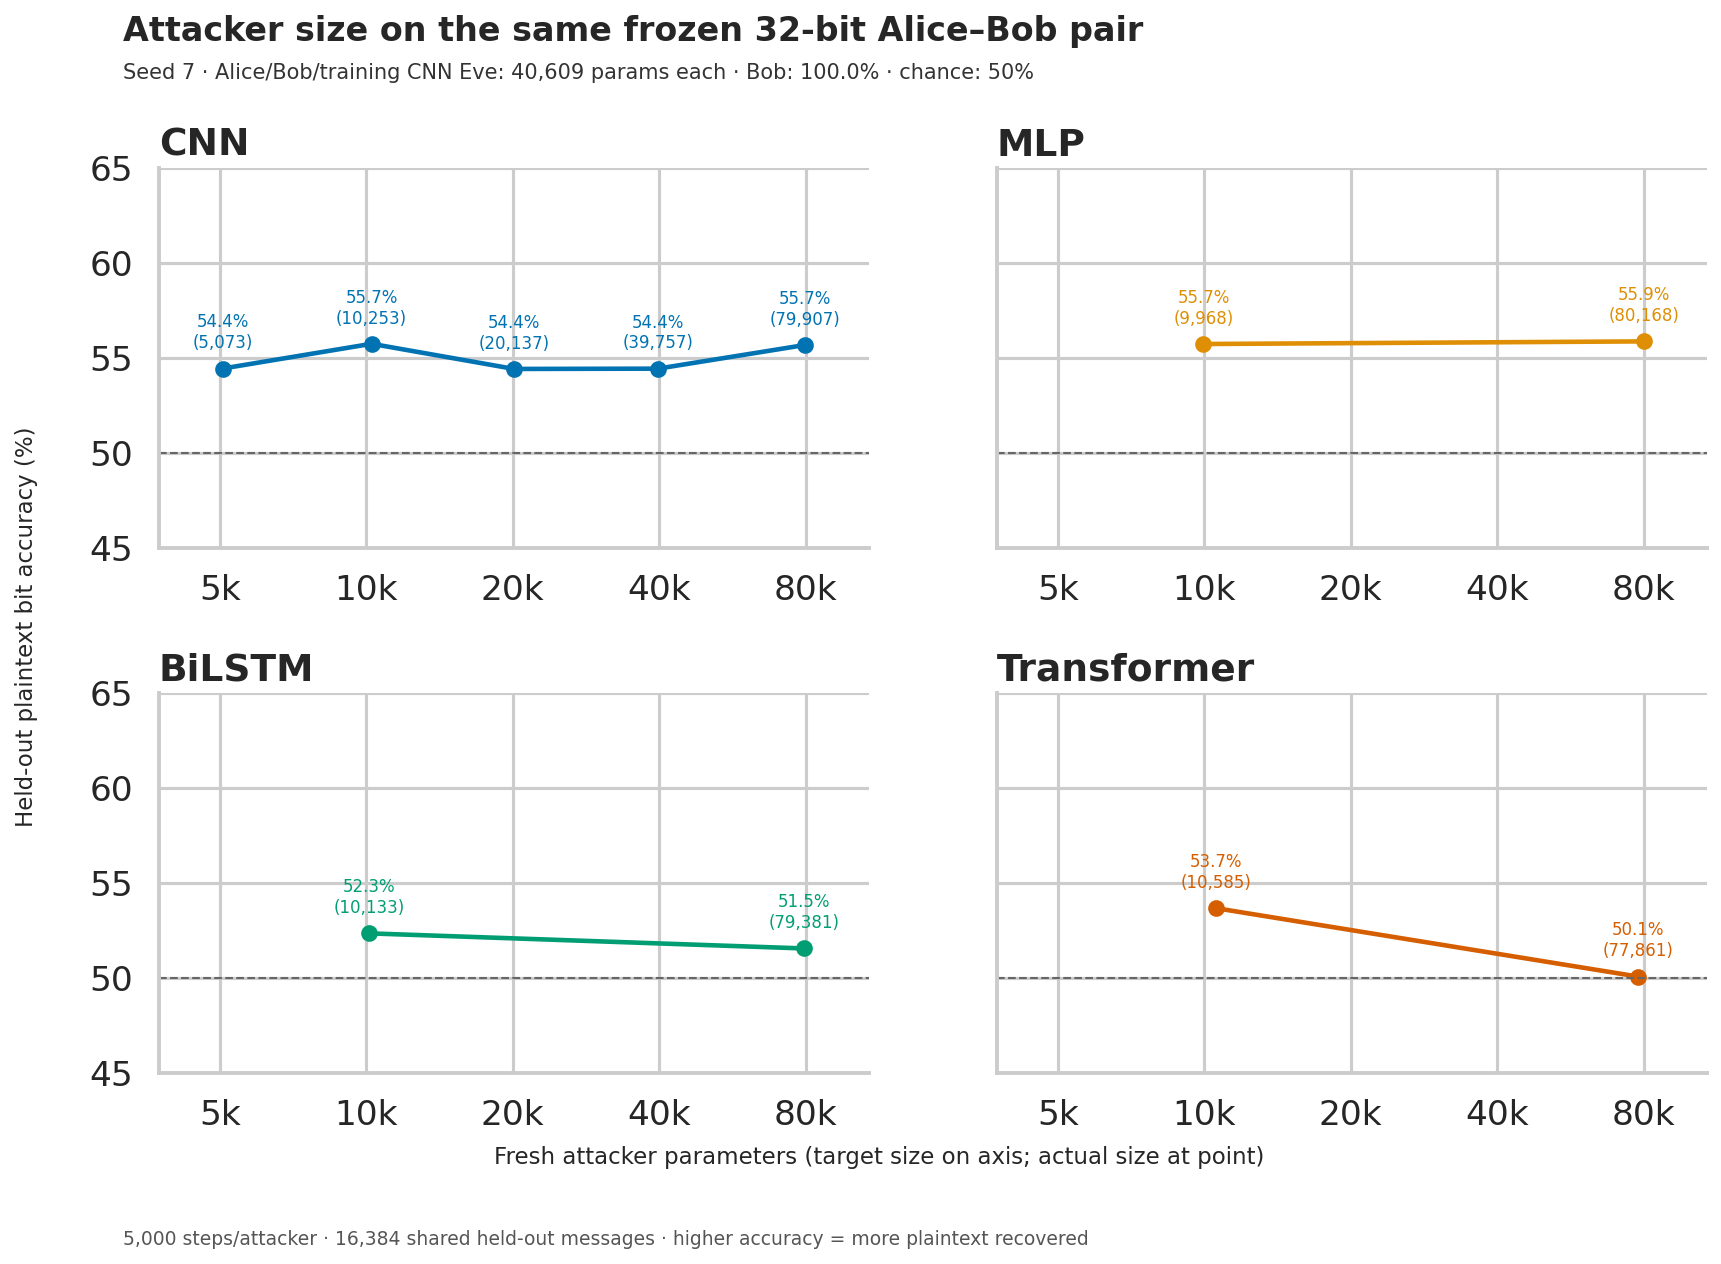

In [ ]:
run_family("CNN")

START MLP target=5,000 actual=5,027 width=45
ATTACK MLP         params=5,027 step=1/5,000 train_bit_accuracy=50.03% elapsed_min=0.0
ATTACK MLP         params=5,027 step=1,000/5,000 train_bit_accuracy=53.83% elapsed_min=0.1
ATTACK MLP         params=5,027 step=2,000/5,000 train_bit_accuracy=54.16% elapsed_min=0.2
ATTACK MLP         params=5,027 step=3,000/5,000 train_bit_accuracy=54.13% elapsed_min=0.3
ATTACK MLP         params=5,027 step=4,000/5,000 train_bit_accuracy=54.17% elapsed_min=0.4
ATTACK MLP         params=5,027 step=5,000/5,000 train_bit_accuracy=54.20% elapsed_min=0.5
RESULT_JSON {"family": "MLP", "target_params": 5000, "actual_params": 5027, "width": 45, "bit_accuracy": 0.5428218841552734, "full_message_accuracy": 0.0, "seed": 7, "train_steps": 5000, "eval_messages": 16384}
SKIP MLP target=10,000: result already in memory
START MLP target=20,000 actual=19,968 width=112
ATTACK MLP         params=19,968 step=1/5,000 train_bit_accuracy=49.96% elapsed_min=0.0
ATTACK MLP       

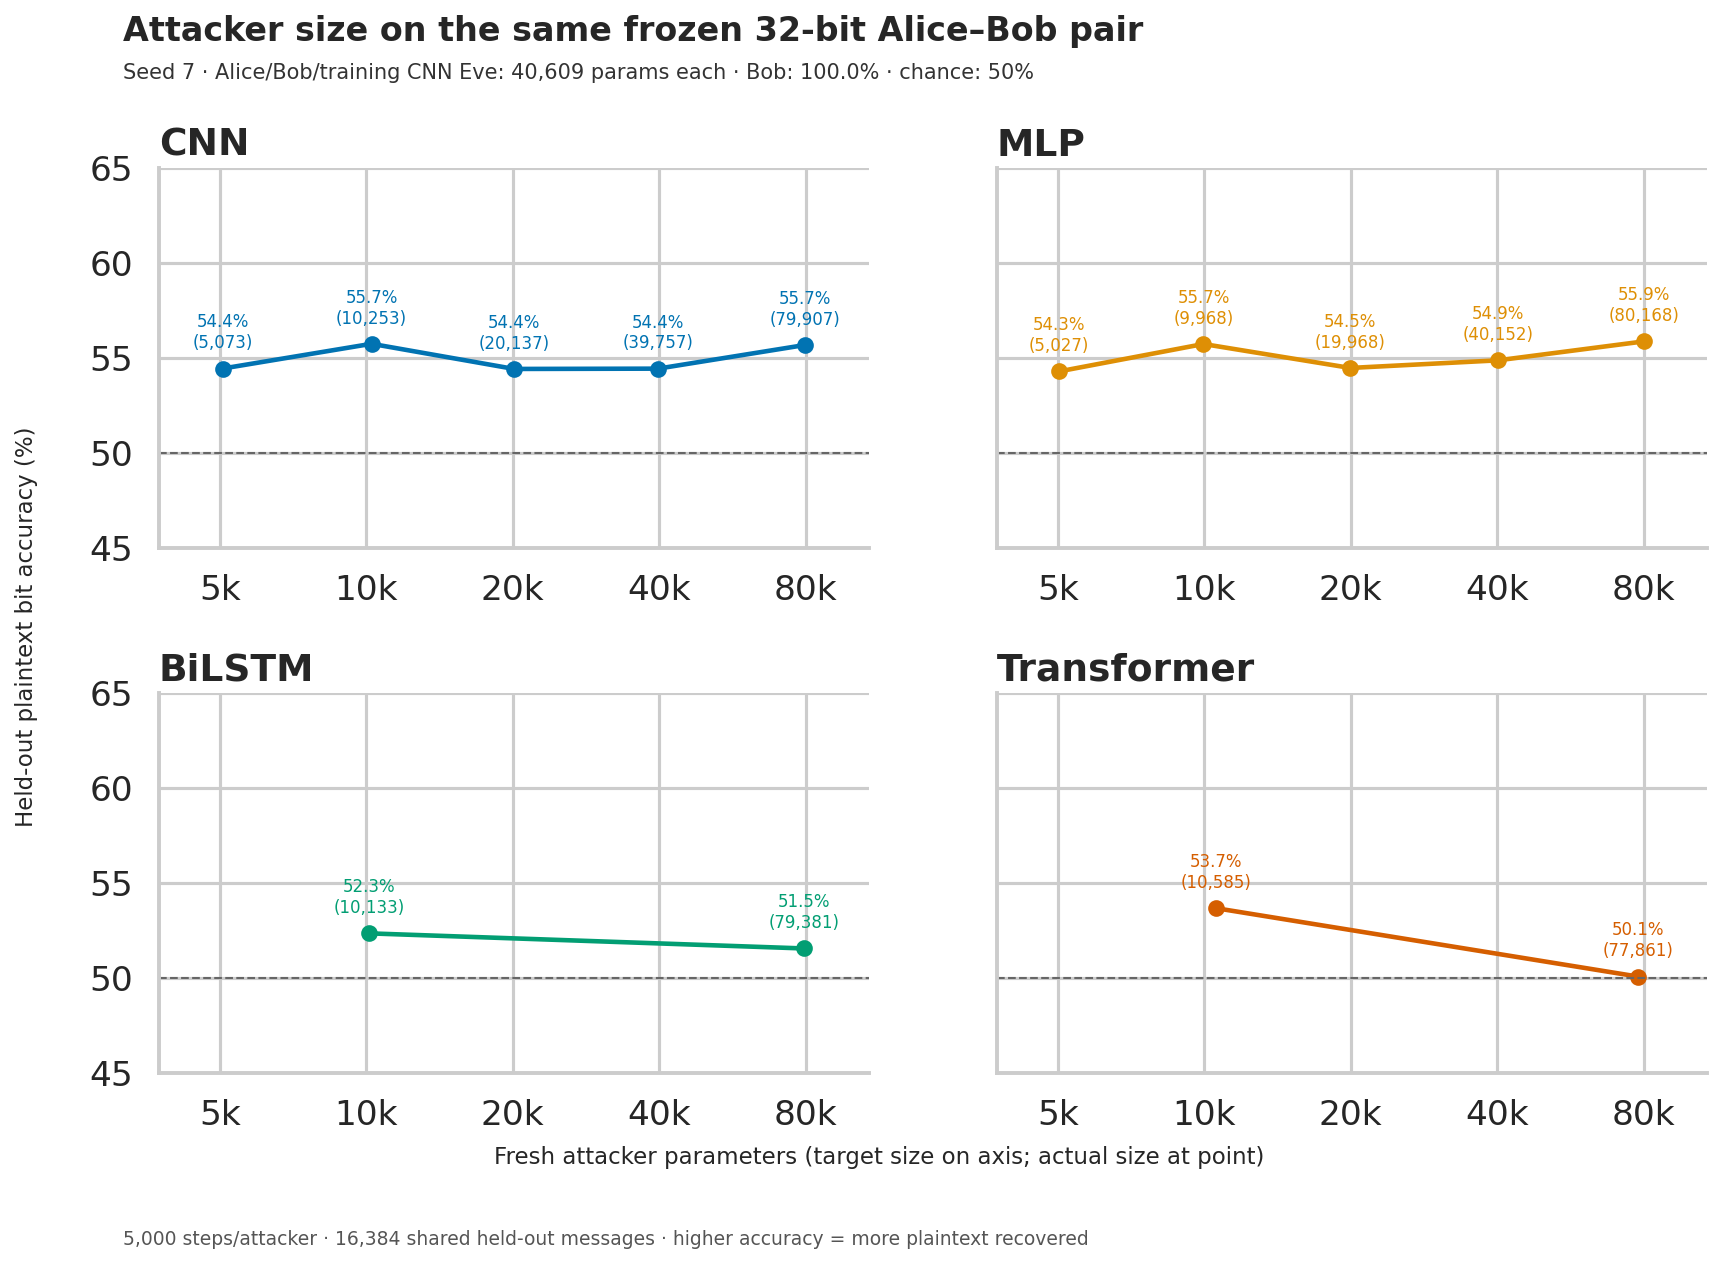

In [ ]:
run_family("MLP")

START BiLSTM target=5,000 actual=4,831 width=23
ATTACK BiLSTM      params=4,831 step=1/5,000 train_bit_accuracy=50.01% elapsed_min=0.0
ATTACK BiLSTM      params=4,831 step=1,000/5,000 train_bit_accuracy=50.92% elapsed_min=0.3
ATTACK BiLSTM      params=4,831 step=2,000/5,000 train_bit_accuracy=51.43% elapsed_min=0.6
ATTACK BiLSTM      params=4,831 step=3,000/5,000 train_bit_accuracy=51.68% elapsed_min=0.9
ATTACK BiLSTM      params=4,831 step=4,000/5,000 train_bit_accuracy=51.87% elapsed_min=1.2
ATTACK BiLSTM      params=4,831 step=5,000/5,000 train_bit_accuracy=51.93% elapsed_min=1.5
RESULT_JSON {"family": "BiLSTM", "target_params": 5000, "actual_params": 4831, "width": 23, "bit_accuracy": 0.5209388732910156, "full_message_accuracy": 0.0, "seed": 7, "train_steps": 5000, "eval_messages": 16384}
SKIP BiLSTM target=10,000: result already in memory
START BiLSTM target=20,000 actual=19,681 width=48
ATTACK BiLSTM      params=19,681 step=1/5,000 train_bit_accuracy=49.99% elapsed_min=0.0
ATTACK

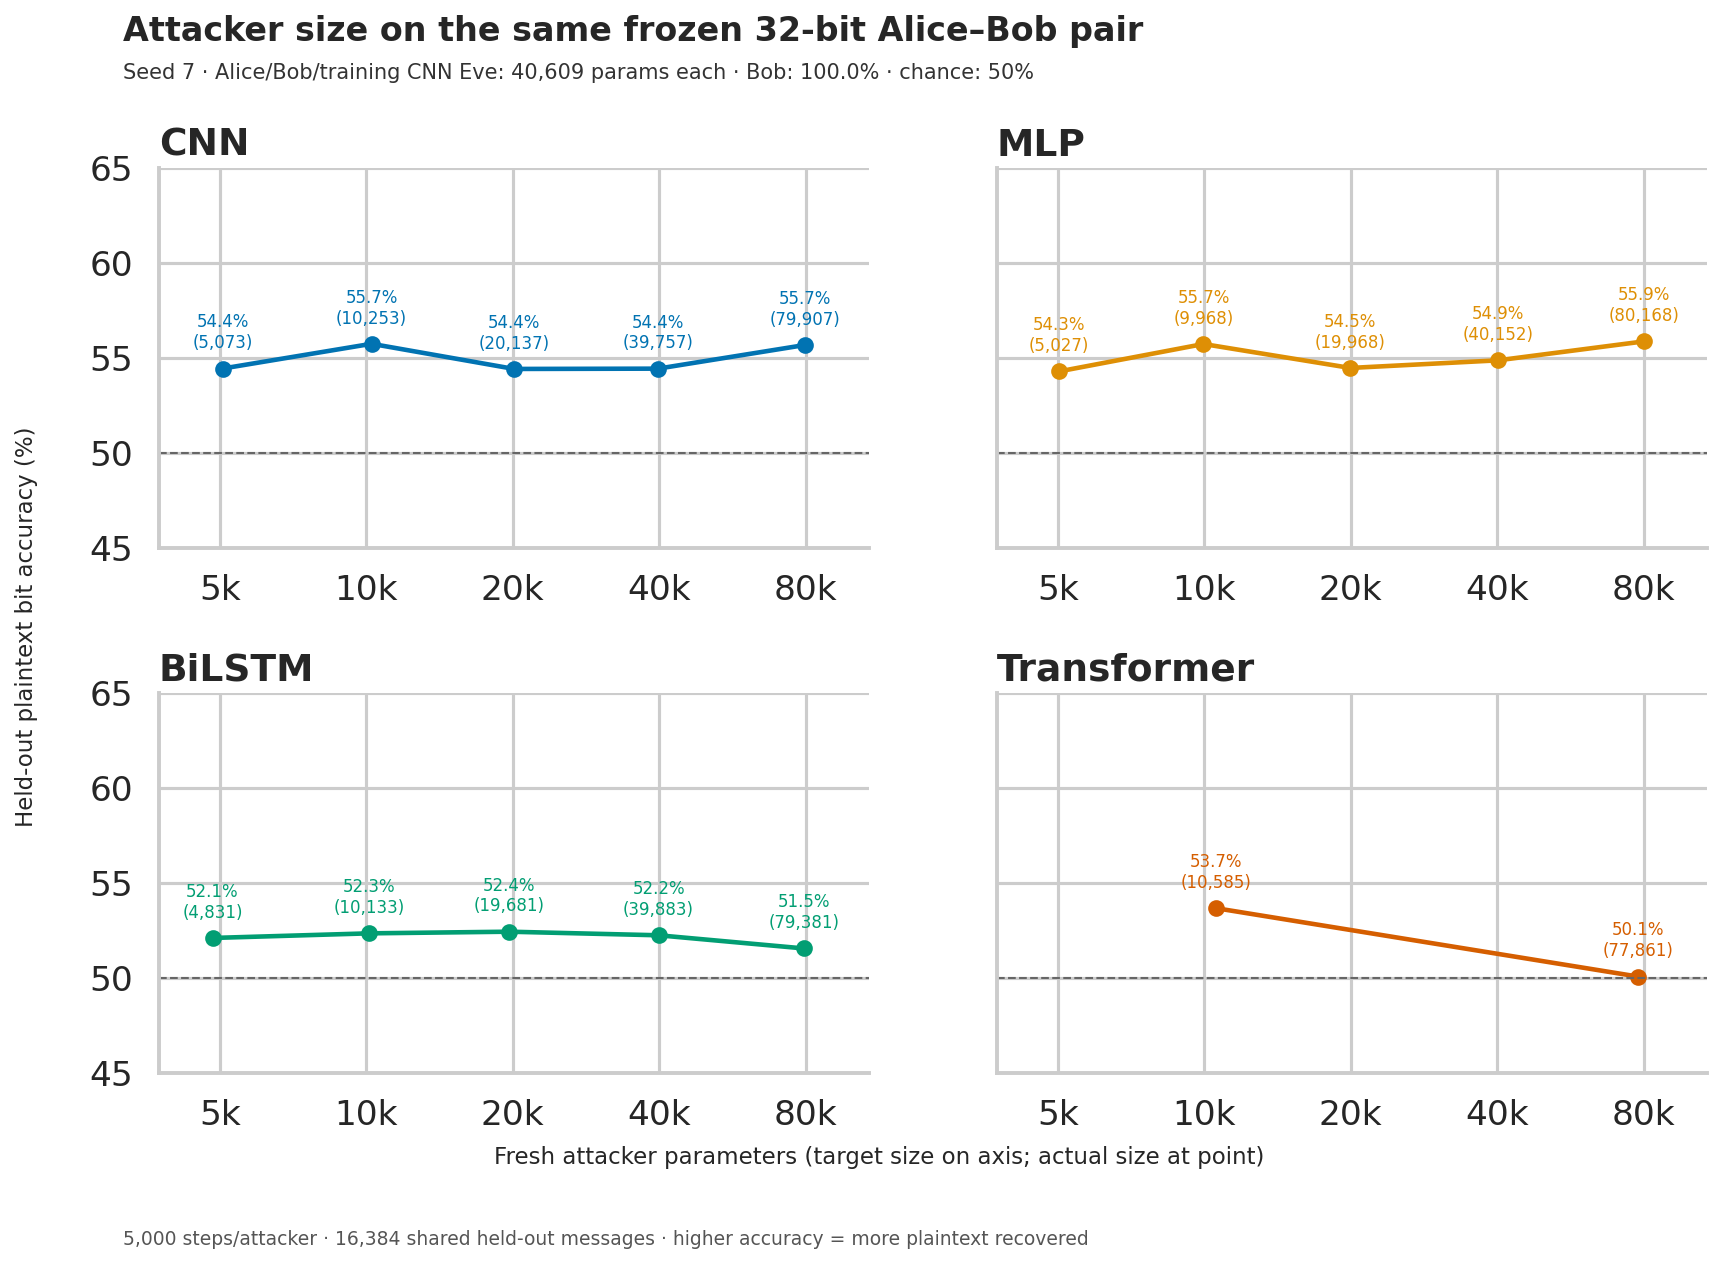

In [ ]:
run_family("BiLSTM")

START Transformer target=5,000 actual=5,009 width=16
ATTACK Transformer params=5,009 step=1/5,000 train_bit_accuracy=49.99% elapsed_min=0.0
ATTACK Transformer params=5,009 step=1,000/5,000 train_bit_accuracy=52.86% elapsed_min=0.6
ATTACK Transformer params=5,009 step=2,000/5,000 train_bit_accuracy=53.47% elapsed_min=1.2
ATTACK Transformer params=5,009 step=3,000/5,000 train_bit_accuracy=53.46% elapsed_min=1.9
ATTACK Transformer params=5,009 step=4,000/5,000 train_bit_accuracy=53.68% elapsed_min=2.5
ATTACK Transformer params=5,009 step=5,000/5,000 train_bit_accuracy=53.82% elapsed_min=3.1
RESULT_JSON {"family": "Transformer", "target_params": 5000, "actual_params": 5009, "width": 16, "bit_accuracy": 0.5376110076904297, "full_message_accuracy": 0.0, "seed": 7, "train_steps": 5000, "eval_messages": 16384}
SKIP Transformer target=10,000: result already in memory
START Transformer target=20,000 actual=18,209 width=32
ATTACK Transformer params=18,209 step=1/5,000 train_bit_accuracy=49.99% el

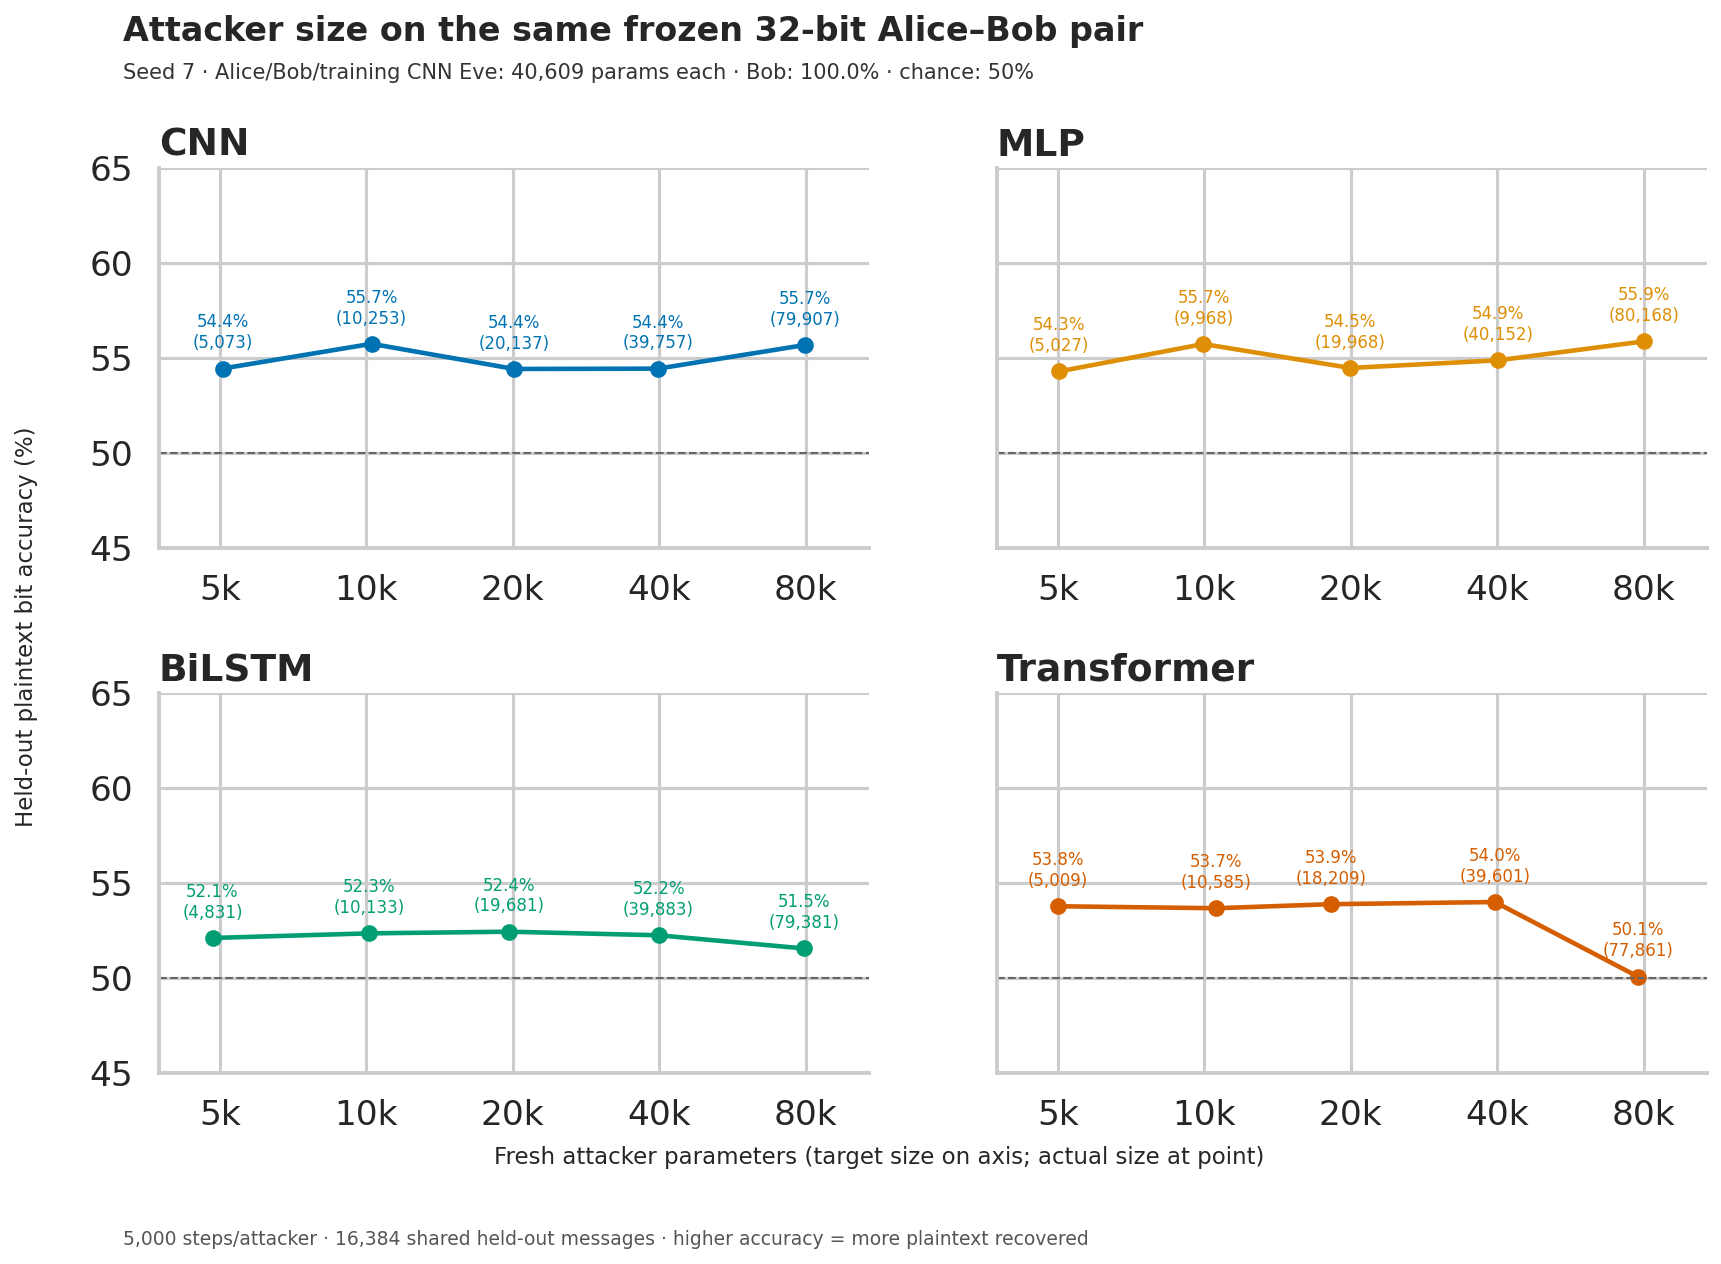

In [ ]:
run_family("Transformer")

In [ ]:
# Final compact summary, printed in addition to the figure above.
expected = len(FAMILIES) * len(TARGET_SIZES)
assert len(results) == expected, f"Only {len(results)} of {expected} attackers finished."
print(f"Seed={SEED}; same frozen Alice/Bob; Bob held-out accuracy={bob_accuracy:.2%}")
print("Architecture  target params  actual params  held-out bit accuracy")
for family in FAMILIES:
    for target in TARGET_SIZES:
        row = next(r for r in results if r["family"] == family
                   and r["target_params"] == target)
        print(f"{family:12s} {target:>10,} {row['actual_params']:>14,} "
              f"{row['bit_accuracy']:>22.2%}")
print("Single seed / one Alice–Bob pair: report these as within-pair observations.")

Seed=7; same frozen Alice/Bob; Bob held-out accuracy=99.99%
Architecture  target params  actual params  held-out bit accuracy
CNN               5,000          5,073                 54.44%
CNN              10,000         10,253                 55.74%
CNN              20,000         20,137                 54.41%
CNN              40,000         39,757                 54.43%
CNN              80,000         79,907                 55.68%
MLP               5,000          5,027                 54.28%
MLP              10,000          9,968                 55.73%
MLP              20,000         19,968                 54.47%
MLP              40,000         40,152                 54.87%
MLP              80,000         80,168                 55.86%
BiLSTM            5,000          4,831                 52.09%
BiLSTM           10,000         10,133                 52.34%
BiLSTM           20,000         19,681                 52.42%
BiLSTM           40,000         39,883                 52.23%
BiLSTM